# NIRSpec SMDS candidates: JADES-GS-z11 / z13 / z14

Find DJA NIRSpec prism spectra for the four JADES GOODS-S dark-star candidates, download them, and convert to the pipeline `Wavelength` / `Flux` CSV units.

Then query MAST for MIRI spectroscopy (LRS slitted / LRS slitless / IFU) near those sky positions and download the MIRI products.

In [8]:
import os
os.environ["PATH"] = (
    "/data/apps/extern/spack_on/gcc/9.3.0/texlive/20220321-oikenzl6gekq5lsohdm6jnnuj276s2ba/bin/x86_64-linux:"
    + os.environ.get("PATH", "")
)
# Keep BLAS single-threaded for stable Nelder-Mead timing
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u
from astropy.io import fits
from astroquery.mast import Observations
from scipy.integrate import quad
from scipy.interpolate import interp1d
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import minimize

import bagpipes as pipes
import bagpipes.config as cfg

REPO_ROOT = Path(".").resolve()
DATA_DIR = REPO_ROOT / "data"
CATALOG = DATA_DIR / "dja_nirspec_z>9_grade3.csv"
FITS_DIR = DATA_DIR / "nirspec_x1d"
CSV_DIR = DATA_DIR / "nirspec_spectra_csv"
MIRI_FITS_DIR = DATA_DIR / "miri_x1d_for_nirspec_candidates"
MIRI_CSV_DIR = DATA_DIR / "miri_spectra_csv_for_nirspec_candidates"
TEMPLATE_DIR = REPO_ROOT / "tlusty_templates"
DJA_BASE = "https://s3.amazonaws.com/msaexp-nirspec/extractions"
# LRS slit: ~0.5" wide; match on pointing center only
MIRI_LRS_SLIT_MATCH_RADIUS = 1 * u.arcsec
MIRI_LRS_SLIT_QUERY_RADIUS = 5 * u.arcsec
# LRS slitless: prism on MIRI imager (~74" x 113"); prefer footprint
MIRI_LRS_SLITLESS_QUERY_RADIUS = 90 * u.arcsec
MIRI_LRS_SLITLESS_POINTING_FALLBACK = 60 * u.arcsec
# IFU/MRS: FOV ~3-8" (larger for mosaics); prefer footprint, else pointing
MIRI_IFU_QUERY_RADIUS = 30 * u.arcsec
MIRI_IFU_POINTING_FALLBACK = 10 * u.arcsec

FITS_DIR.mkdir(parents=True, exist_ok=True)
CSV_DIR.mkdir(parents=True, exist_ok=True)
MIRI_FITS_DIR.mkdir(parents=True, exist_ok=True)
MIRI_CSV_DIR.mkdir(parents=True, exist_ok=True)

GALAXY_UNIT_SCALE = 1e21
SMDS_UNIT_SCALE = 1.0
COSMO_SMDS = dict(H0=72.0, Om=0.27)
COSMO_GALAXY = dict(H0=70.0, Om=0.3)
C_CGS = 2.99792458e10
LOGM_DS_MIN, LOGM_DS_MAX = 5.0, 8.5
LOGM_GAL_MIN, LOGM_GAL_MAX = 6.0, 11.0
PLOT_LAM_MAX_UM = 12.0  # extend model curves past NIRSpec
NIRSPEC_R = 100.0       # prism resolving power used in the galaxy kernel

cfg.max_redshift = 30
for _flag in ("apply_igm", "use_igm", "include_igm"):
    if hasattr(cfg, _flag):
        setattr(cfg, _flag, False)

# Prefer LaTeX text if the local texlive path works; fall back to mathtext
try:
    plt.rcParams.update({
        "text.usetex": True,
        "font.family": "serif",
        "axes.grid": False,
    })
    fig = plt.figure()
    plt.close(fig)
except Exception:
    plt.rcParams.update({
        "text.usetex": False,
        "mathtext.fontset": "stix",
        "axes.grid": False,
    })


## 1. Locate the four candidates in the DJA grade-3 catalog

Literature names are matched to DJA `root` + `srcid` (prism-CLEAR rows). Redshifts used in the fit are the DJA prism values.


In [9]:
# Literature IDs -> DJA extraction keys (GOODS-S / JADES)
TARGET_KEYS = [
    dict(name="JADES-GS-z14-0", root="jades-gds10-v4", srcid=183348, z_lit=14.18),
    dict(name="JADES-GS-z14-1", root="jades-gds10-v4", srcid=20018044, z_lit=13.90),
    dict(name="JADES-GS-z13",   root="gds-udeep-v4",   srcid=20128771, z_lit=13.20),
    dict(name="JADES-GS-z11",   root="gds-deep-v4",    srcid=14220,    z_lit=11.58),
]

dja = pd.read_csv(CATALOG)

def pick_prism_row(root, srcid):
    # Prefer PRISM_CLEAR; fall back to any grating if needed
    hit = dja[(dja["root"] == root) & (dja["srcid"] == srcid)].copy()
    if hit.empty:
        raise ValueError(f"no DJA row for {root} srcid={srcid}")
    prism = hit[hit["grating"].astype(str).str.contains("PRISM", case=False, na=False)]
    row = prism.iloc[0] if len(prism) else hit.sort_values("exptime", ascending=False).iloc[0]
    return row

targets = []
for key in TARGET_KEYS:
    row = pick_prism_row(key["root"], key["srcid"])
    targets.append({
        **key,
        "ra": float(row["ra"]),
        "dec": float(row["dec"]),
        "z": float(row["z"]),
        "file": str(row["file"]),
        "grating": str(row["grating"]),
        "exptime": float(row["exptime"]),
        "wmin": float(row["wmin"]),
        "wmax": float(row["wmax"]),
    })

targets_df = pd.DataFrame(targets)
targets_df[["name", "root", "srcid", "ra", "dec", "z", "z_lit", "file", "grating", "exptime"]]


,name,root,srcid,ra,dec,z,z_lit,file,grating,exptime
0,JADES-GS-z14-0,jades-gds10-v4,183348,53.082937,-27.855632,14.1793,14.18,jades-gds10-v4_prism-clear_1287_183348.spec.fits,PRISM_CLEAR,33262.7
1,JADES-GS-z14-1,jades-gds10-v4,20018044,53.074270,-27.885919,14.0801,13.90,jades-gds10-v4_prism-clear_1287_20018044.spec....,PRISM_CLEAR,66525.3
2,JADES-GS-z13,gds-udeep-v4,20128771,53.149881,-27.776502,13.1170,13.20,gds-udeep-v4_prism-clear_3215_20128771.spec.fits,PRISM_CLEAR,157997.7
3,JADES-GS-z11,gds-deep-v4,14220,53.164768,-27.774626,11.5936,11.58,gds-deep-v4_prism-clear_1210_14220.spec.fits,PRISM_CLEAR,99788.0


## 2. Download DJA `*.spec.fits` and write pipeline CSVs

Flux in SPEC1D is µJy. Convert to \(f_\lambda \times 10^{21}\) erg s⁻¹ cm⁻² Å⁻¹ to match the SMDS fitting units.


In [10]:
def uJy_to_flambda_1e21(uJy, wavelength_um):
    # microJy -> f_lambda [erg/s/cm^2/A] * 1e21
    jy = np.asarray(uJy, float) * 1e-6
    f_nu = jy * 1e-23
    lam_cm = np.asarray(wavelength_um, float) * 1e-4
    f_per_cm = f_nu * (C_CGS / lam_cm ** 2)
    f_per_A = f_per_cm * 1e-8
    return f_per_A * 1e21


def download_dja_spec(root, filename, out_dir=FITS_DIR):
    # DJA public extractions live under msaexp-nirspec/extractions/{root}/{file}
    out_path = Path(out_dir) / filename
    if out_path.is_file() and out_path.stat().st_size > 0:
        print(f"cached {out_path.name}")
        return out_path
    url = f"{DJA_BASE}/{root}/{filename}"
    print(f"download {url}")
    urlretrieve(url, out_path)
    return out_path


def spec_fits_to_csv(fits_path, csv_path):
    # Write Wavelength [um], Flux, Flux_Error in 1e21 f_lambda units
    with fits.open(fits_path) as hdul:
        sp = hdul["SPEC1D"].data
        wave = np.asarray(sp["wave"], float)
        flux_uJy = np.asarray(sp["flux"], float)
        err_uJy = np.asarray(sp["err"], float)
    flux = uJy_to_flambda_1e21(flux_uJy, wave)
    err = uJy_to_flambda_1e21(err_uJy, wave)
    good = np.isfinite(wave) & np.isfinite(flux) & np.isfinite(err) & (err > 0)
    df = pd.DataFrame({
        "Wavelength": wave[good],
        "Flux": flux[good],
        "Flux_Error": err[good],
    })
    df.to_csv(csv_path, index=False)
    return df


for target in targets:
    fits_path = download_dja_spec(target["root"], target["file"])
    csv_name = f"{target['name'].replace('-', '_')}_nirspec.csv"
    csv_path = CSV_DIR / csv_name
    df = spec_fits_to_csv(fits_path, csv_path)
    target["fits_path"] = str(fits_path)
    target["csv_path"] = str(csv_path)
    target["n_pix"] = len(df)
    print(f"{target['name']}: {len(df)} pixels, "
          f"λ=[{df['Wavelength'].min():.2f}, {df['Wavelength'].max():.2f}] µm -> {csv_path.name}")


cached jades-gds10-v4_prism-clear_1287_183348.spec.fits
JADES-GS-z14-0: 467 pixels, λ=[0.55, 5.50] µm -> JADES_GS_z14_0_nirspec.csv
cached jades-gds10-v4_prism-clear_1287_20018044.spec.fits
JADES-GS-z14-1: 467 pixels, λ=[0.55, 5.50] µm -> JADES_GS_z14_1_nirspec.csv
cached gds-udeep-v4_prism-clear_3215_20128771.spec.fits
JADES-GS-z13: 468 pixels, λ=[0.55, 5.50] µm -> JADES_GS_z13_nirspec.csv
cached gds-deep-v4_prism-clear_1210_14220.spec.fits
JADES-GS-z11: 467 pixels, λ=[0.55, 5.50] µm -> JADES_GS_z11_nirspec.csv


## 3. Search MAST for MIRI spectroscopy for these candidates

Search criteria for different modes:
- **LRS slit:** Pointing sep <= 1"
- **LRS slitless:** Source inside `s_region`; if missing, pointing sep <= 60"(imager-scale)
- **IFU / MRS:** Source inside `s_region`; if missing, pointing sep <= 10"

In [11]:
from matplotlib.path import Path as MplPath


def is_imaging_obs_id(obs_id):
    # MAST sometimes tags imaging rows as MIRI/SLIT; drop by product name
    return "mirimage" in str(obs_id).lower()


def s_region_contains(ra_deg, dec_deg, s_region):
    # True/False if polygon/circle usable; None if missing or unparsed
    if s_region is None:
        return None
    text = str(s_region).strip()
    if not text or text.lower() in ("nan", "none", "--"):
        return None
    upper = text.upper()
    tokens = text.replace(",", " ").split()
    numbers = []
    for token in tokens:
        try:
            numbers.append(float(token))
        except ValueError:
            continue
    if "CIRCLE" in upper and len(numbers) >= 3:
        # CIRCLE ICRS ra dec radius_deg
        center = SkyCoord(numbers[0], numbers[1], unit="deg")
        source = SkyCoord(ra_deg, dec_deg, unit="deg")
        return source.separation(center).deg <= numbers[2]
    if "POLYGON" in upper and len(numbers) >= 6:
        lons = numbers[0::2]
        lats = numbers[1::2]
        if len(lons) != len(lats) or len(lons) < 3:
            return None
        # Local RA/Dec path is fine at arcsec scales (GOODS-S, no RA wrap)
        return bool(MplPath(list(zip(lons, lats))).contains_point((ra_deg, dec_deg)))
    return None


def query_miri_mode(ra_deg, dec_deg, instrument_names, radius):
    # Cone search for discovery only; caller applies pointing/footprint cuts
    try:
        return Observations.query_criteria(
            obs_collection="JWST",
            instrument_name=instrument_names,
            coordinates=f"{ra_deg} {dec_deg}",
            radius=f"{radius.to(u.arcsec).value}s",
        )
    except Exception:
        # astroquery raises when MAST returns zero rows
        return None


def score_pointing_row(coord, row, mode, match_radius, reason_ok, reason_far):
    # Slit LRS: require source near the targeted pointing
    obs_id = str(row["obs_id"])
    if is_imaging_obs_id(obs_id):
        return None
    pointing = SkyCoord(float(row["s_ra"]), float(row["s_dec"]), unit="deg")
    sep = coord.separation(pointing).to(u.arcsec).value
    keep = sep <= match_radius.to(u.arcsec).value
    return {
        "mode": mode,
        "sep_arcsec": float(sep),
        "in_footprint": None,
        "is_match": bool(keep),
        "match_reason": reason_ok if keep else reason_far,
        "obs_id": obs_id,
        "instrument_name": str(row["instrument_name"]),
        "proposal_id": str(row["proposal_id"]),
        "t_exptime": float(row["t_exptime"]) if np.isfinite(row["t_exptime"]) else np.nan,
        "s_ra": float(row["s_ra"]),
        "s_dec": float(row["s_dec"]),
    }


def score_footprint_row(coord, row, mode, pointing_fallback, reason_in, reason_out, reason_ok_pt, reason_far_pt):
    # Slitless / IFU: prefer s_region containment; else pointing fallback
    obs_id = str(row["obs_id"])
    if is_imaging_obs_id(obs_id):
        return None
    pointing = SkyCoord(float(row["s_ra"]), float(row["s_dec"]), unit="deg")
    sep = coord.separation(pointing).to(u.arcsec).value
    s_region = row["s_region"] if "s_region" in row.colnames else None
    in_footprint = s_region_contains(coord.ra.deg, coord.dec.deg, s_region)
    if in_footprint is True:
        keep, reason = True, reason_in
    elif in_footprint is False:
        keep, reason = False, reason_out
    else:
        keep = sep <= pointing_fallback.to(u.arcsec).value
        reason = reason_ok_pt if keep else reason_far_pt
    return {
        "mode": mode,
        "sep_arcsec": float(sep),
        "in_footprint": in_footprint,
        "is_match": bool(keep),
        "match_reason": reason,
        "obs_id": obs_id,
        "instrument_name": str(row["instrument_name"]),
        "proposal_id": str(row["proposal_id"]),
        "t_exptime": float(row["t_exptime"]) if np.isfinite(row["t_exptime"]) else np.nan,
        "s_ra": float(row["s_ra"]),
        "s_dec": float(row["s_dec"]),
    }


In [12]:
miri_nearby_rows = []
miri_summary_rows = []

# (label, instruments, query_radius, scorer kwargs builder)
MODE_QUERIES = [
    (
        "LRS_SLIT",
        ["MIRI/SLIT"],
        MIRI_LRS_SLIT_QUERY_RADIUS,
        lambda coord, row: score_pointing_row(
            coord, row, "LRS_SLIT",
            MIRI_LRS_SLIT_MATCH_RADIUS,
            "lrs_slit_pointing_le_1arcsec",
            "lrs_slit_pointing_too_far",
        ),
    ),
    (
        "LRS_SLITLESS",
        ["MIRI/SLITLESS"],
        MIRI_LRS_SLITLESS_QUERY_RADIUS,
        lambda coord, row: score_footprint_row(
            coord, row, "LRS_SLITLESS",
            MIRI_LRS_SLITLESS_POINTING_FALLBACK,
            "lrs_slitless_in_footprint",
            "lrs_slitless_outside_footprint",
            "lrs_slitless_pointing_le_60arcsec",
            "lrs_slitless_pointing_too_far",
        ),
    ),
    (
        "IFU",
        ["MIRI/IFU"],
        MIRI_IFU_QUERY_RADIUS,
        lambda coord, row: score_footprint_row(
            coord, row, "IFU",
            MIRI_IFU_POINTING_FALLBACK,
            "ifu_in_footprint",
            "ifu_outside_footprint",
            "ifu_pointing_le_10arcsec",
            "ifu_pointing_too_far",
        ),
    ),
]

for target in targets:
    coord = SkyCoord(target["ra"], target["dec"], unit="deg")
    scored = []

    for _mode_name, instruments, query_radius, score_fn in MODE_QUERIES:
        table = query_miri_mode(target["ra"], target["dec"], instruments, query_radius)
        if table is None:
            continue
        for row in table:
            result = score_fn(coord, row)
            if result is not None:
                scored.append(result)

    for result in scored:
        miri_nearby_rows.append({
            "name": target["name"],
            "ra": target["ra"],
            "dec": target["dec"],
            **result,
        })

    matches = [result for result in scored if result["is_match"]]
    slit_matches = [result for result in matches if result["mode"] == "LRS_SLIT"]
    slitless_matches = [result for result in matches if result["mode"] == "LRS_SLITLESS"]
    ifu_matches = [result for result in matches if result["mode"] == "IFU"]
    nearest = min(scored, key=lambda result: result["sep_arcsec"]) if scored else None

    miri_summary_rows.append({
        "name": target["name"],
        "ra": target["ra"],
        "dec": target["dec"],
        "n_lrs_slit_match": len(slit_matches),
        "n_lrs_slitless_match": len(slitless_matches),
        "n_ifu_match": len(ifu_matches),
        "has_lrs_slit": len(slit_matches) > 0,
        "has_lrs_slitless": len(slitless_matches) > 0,
        "has_ifu": len(ifu_matches) > 0,
        "has_miri_spec": len(matches) > 0,
        "nearest_sep_arcsec": nearest["sep_arcsec"] if nearest else np.nan,
        "nearest_mode": nearest["mode"] if nearest else "",
        "nearest_obs_id": nearest["obs_id"] if nearest else "",
        "nearest_match_reason": nearest["match_reason"] if nearest else "",
        "best_lrs_slit_obs_id": slit_matches[0]["obs_id"] if slit_matches else "",
        "best_lrs_slitless_obs_id": slitless_matches[0]["obs_id"] if slitless_matches else "",
        "best_ifu_obs_id": ifu_matches[0]["obs_id"] if ifu_matches else "",
    })

    if not scored:
        print(f"{target['name']}: no MIRI spectroscopy rows in query cones")
    else:
        print(
            f"{target['name']}: slit={len(slit_matches)}, "
            f"slitless={len(slitless_matches)}, IFU={len(ifu_matches)}; "
            f"nearest {nearest['sep_arcsec']:.2f} arcsec "
            f"{nearest['obs_id']} ({nearest['mode']}, {nearest['match_reason']})"
        )

miri_summary_df = pd.DataFrame(miri_summary_rows)
miri_nearby_df = pd.DataFrame(miri_nearby_rows)
if len(miri_nearby_df):
    miri_nearby_df = miri_nearby_df.sort_values(
        ["name", "is_match", "sep_arcsec"], ascending=[True, False, True]
    )

miri_summary_df

JADES-GS-z14-0: slit=4, slitless=0, IFU=0; nearest 0.00 arcsec jw08544-o001_t001_miri_p750l (LRS_SLIT, lrs_slit_pointing_le_1arcsec)
JADES-GS-z14-1: no MIRI spectroscopy rows in query cones
JADES-GS-z13: slit=0, slitless=0, IFU=0; nearest 7.65 arcsec jw05279-o003_t006_miri_ch1-medium (IFU, ifu_outside_footprint)
JADES-GS-z11: slit=0, slitless=0, IFU=0; nearest 25.09 arcsec jw05279-o005_t004_miri_ch4-long (IFU, ifu_outside_footprint)


,name,ra,dec,n_lrs_slit_match,n_lrs_slitless_match,n_ifu_match,has_lrs_slit,has_lrs_slitless,has_ifu,has_miri_spec,nearest_sep_arcsec,nearest_mode,nearest_obs_id,nearest_match_reason,best_lrs_slit_obs_id,best_lrs_slitless_obs_id,best_ifu_obs_id
0,JADES-GS-z14-0,53.082937,-27.855632,4,0,0,True,False,False,True,0.004440,LRS_SLIT,jw08544-o001_t001_miri_p750l,lrs_slit_pointing_le_1arcsec,jw08544-o001_t001_miri_p750l,,
1,JADES-GS-z14-1,53.074270,-27.885919,0,0,0,False,False,False,False,NaN,,,,,,
2,JADES-GS-z13,53.149881,-27.776502,0,0,0,False,False,False,False,7.652892,IFU,jw05279-o003_t006_miri_ch1-medium,ifu_outside_footprint,,,
3,JADES-GS-z11,53.164768,-27.774626,0,0,0,False,False,False,False,25.094089,IFU,jw05279-o005_t004_miri_ch4-long,ifu_outside_footprint,,,


## 4. Download MIRI Level-3 `x1d` for matches

Download rows with `is_match=True`. Proprietary files are logged as `proprietary`.

In [13]:
def find_l3_x1d_products(obs_id):
    # L3 SCIENCE X1D FITS for one MAST obs_id (empty table if none)
    obs_rows = Observations.query_criteria(obs_collection="JWST", obs_id=obs_id)
    if len(obs_rows) == 0:
        return obs_rows
    products = Observations.get_product_list(obs_rows)
    return Observations.filter_products(
        products,
        productType="SCIENCE",
        productSubGroupDescription="X1D",
        calib_level=[3],
        extension="fits",
    )


def resolve_download_obs_id(matched_obs_id, ra_deg, dec_deg, search_radius="30s"):
    # Prefer matched obs_id; else nearest association with an L3 X1D
    products = find_l3_x1d_products(matched_obs_id)
    if len(products) > 0:
        return matched_obs_id, products, "matched"

    nearby = Observations.query_criteria(
        obs_collection="JWST",
        instrument_name=["MIRI/SLIT", "MIRI/SLITLESS", "MIRI/IFU"],
        coordinates=f"{ra_deg} {dec_deg}",
        radius=search_radius,
    )
    if len(nearby) == 0:
        return matched_obs_id, products, "missing"

    is_assoc = np.array([("-o" in oid) and ("xx" not in oid) for oid in nearby["obs_id"]])
    candidates = nearby[is_assoc] if is_assoc.any() else nearby
    target_coord = SkyCoord(ra_deg, dec_deg, unit="deg")
    cand_coords = SkyCoord(candidates["s_ra"], candidates["s_dec"], unit="deg")
    order = np.argsort(target_coord.separation(cand_coords))

    for index in order:
        candidate_obs_id = str(candidates["obs_id"][index])
        candidate_products = find_l3_x1d_products(candidate_obs_id)
        if len(candidate_products) > 0:
            return candidate_obs_id, candidate_products, "fallback"
    return matched_obs_id, products, "missing"


def jy_to_flambda_1e21(jy, wavelength_um):
    # Jy -> f_lambda [erg/s/cm^2/A] * 1e21 (same units as NIRSpec CSVs)
    f_nu = np.asarray(jy, float) * 1e-23
    lam_cm = np.asarray(wavelength_um, float) * 1e-4
    f_per_cm = f_nu * (C_CGS / lam_cm ** 2)
    return f_per_cm * 1e-8 * 1e21


def miri_x1d_to_csv(fits_path, csv_path):
    # MIRI L3 x1d EXTRACT1D: WAVELENGTH [um], FLUX/FLUX_ERROR [Jy]
    with fits.open(fits_path) as hdul:
        sp = hdul["EXTRACT1D"].data
        wave = np.asarray(sp["WAVELENGTH"], float)
        flux_jy = np.asarray(sp["FLUX"], float)
        err_jy = np.asarray(sp["FLUX_ERROR"], float)
    flux = jy_to_flambda_1e21(flux_jy, wave)
    err = jy_to_flambda_1e21(err_jy, wave)
    good = np.isfinite(wave) & np.isfinite(flux) & np.isfinite(err) & (err > 0)
    df = pd.DataFrame({
        "Wavelength": wave[good],
        "Flux": flux[good],
        "Flux_Error": err[good],
    })
    df.to_csv(csv_path, index=False)
    return df

In [ ]:
hits = (
    miri_nearby_df[miri_nearby_df["is_match"]].copy()
    if len(miri_nearby_df) and "is_match" in miri_nearby_df.columns
    else pd.DataFrame()
)
download_rows = []

if hits.empty:
    print("No MIRI spectroscopy matches.")
else:
    unique_hits = hits.drop_duplicates(subset=["name", "obs_id"], keep="first")
    for _, hit in unique_hits.iterrows():
        matched_obs_id = str(hit["obs_id"])
        download_obs_id, products, status = resolve_download_obs_id(
            matched_obs_id, float(hit["ra"]), float(hit["dec"])
        )
        local_path = ""
        product_name = ""
        csv_path = ""
        n_pix = 0

        if status != "missing" and len(products) > 0:
            preferred_name = f"{download_obs_id}_x1d.fits"
            if preferred_name in list(products["productFilename"]):
                chosen_table = products[products["productFilename"] == preferred_name]
            else:
                chosen_table = products[[0]]
            product_name = str(chosen_table["productFilename"][0])
            manifest = Observations.download_products(
                chosen_table,
                download_dir=str(MIRI_FITS_DIR),
                mrp_only=False,
            )
            local_path = str(manifest["Local Path"][0])
            download_status = str(manifest["Status"][0])
            message = str(manifest["Message"][0]) if "Message" in manifest.colnames else ""
            if download_status != "COMPLETE" or not Path(local_path).is_file():
                status = "proprietary" if "401" in message else "download_failed"
                local_path = ""
                print(f"{hit['name']} {matched_obs_id}: {status} ({download_status}) {message}")
            else:
                csv_name = (
                    f"{hit['name'].replace('-', '_')}_{hit['mode']}_"
                    f"{download_obs_id}_miri.csv"
                )
                csv_file = MIRI_CSV_DIR / csv_name
                df = miri_x1d_to_csv(local_path, csv_file)
                csv_path = str(csv_file)
                n_pix = len(df)
                print(
                    f"{hit['name']} [{hit['mode']}] {matched_obs_id}: "
                    f"{status} -> {product_name} ({n_pix} pix)"
                )
        else:
            print(f"{hit['name']} [{hit['mode']}] {matched_obs_id}: {status} -> NONE")

        download_rows.append({
            "name": hit["name"],
            "mode": hit["mode"],
            "match_reason": hit["match_reason"],
            "sep_arcsec": float(hit["sep_arcsec"]),
            "miri_obs_id_matched": matched_obs_id,
            "miri_obs_id_download": download_obs_id,
            "instrument_name": hit["instrument_name"],
            "proposal_id": hit["proposal_id"],
            "resolve_status": status,
            "productFilename": product_name,
            "local_fits": local_path,
            "csv_path": csv_path,
            "n_pix": n_pix,
        })

miri_download_df = pd.DataFrame(download_rows)
miri_download_path = DATA_DIR / "nirspec_candidates_miri_x1d_download.csv"
miri_download_df.to_csv(miri_download_path, index=False)
print(f"wrote {miri_download_path.name}")
miri_download_df

JADES-GS-z14-0 [LRS_SLIT] jw08544-o001_t001_miri_p750l: matched -> jw08544-o001_t001_miri_p750l_x1d.fits (389 pix)
JADES-GS-z14-0 [LRS_SLIT] jw08544-o004_t001_miri_p750l: matched -> jw08544-o004_t001_miri_p750l_x1d.fits (389 pix)
JADES-GS-z14-0 [LRS_SLIT] jw08544-o002_t001_miri_p750l: matched -> jw08544-o002_t001_miri_p750l_x1d.fits (389 pix)
JADES-GS-z14-0 [LRS_SLIT] jw08544-o003_t001_miri_p750l: matched -> jw08544-o003_t001_miri_p750l_x1d.fits (389 pix)
wrote nirspec_candidates_miri_x1d_download.csv


,name,mode,match_reason,sep_arcsec,miri_obs_id_matched,miri_obs_id_download,instrument_name,proposal_id,resolve_status,productFilename,local_fits,csv_path,n_pix
0,JADES-GS-z14-0,LRS_SLIT,lrs_slit_pointing_le_1arcsec,0.00444,jw08544-o001_t001_miri_p750l,jw08544-o001_t001_miri_p750l,MIRI/SLIT,8544,matched,jw08544-o001_t001_miri_p750l_x1d.fits,/home/yzhan629/DS_MIRI/data/miri_x1d_for_nirsp...,/home/yzhan629/DS_MIRI/data/miri_spectra_csv_f...,389
1,JADES-GS-z14-0,LRS_SLIT,lrs_slit_pointing_le_1arcsec,0.00444,jw08544-o004_t001_miri_p750l,jw08544-o004_t001_miri_p750l,MIRI/SLIT,8544,matched,jw08544-o004_t001_miri_p750l_x1d.fits,/home/yzhan629/DS_MIRI/data/miri_x1d_for_nirsp...,/home/yzhan629/DS_MIRI/data/miri_spectra_csv_f...,389
2,JADES-GS-z14-0,LRS_SLIT,lrs_slit_pointing_le_1arcsec,0.00444,jw08544-o002_t001_miri_p750l,jw08544-o002_t001_miri_p750l,MIRI/SLIT,8544,matched,jw08544-o002_t001_miri_p750l_x1d.fits,/home/yzhan629/DS_MIRI/data/miri_x1d_for_nirsp...,/home/yzhan629/DS_MIRI/data/miri_spectra_csv_f...,389
3,JADES-GS-z14-0,LRS_SLIT,lrs_slit_pointing_le_1arcsec,0.00444,jw08544-o003_t001_miri_p750l,jw08544-o003_t001_miri_p750l,MIRI/SLIT,8544,matched,jw08544-o003_t001_miri_p750l_x1d.fits,/home/yzhan629/DS_MIRI/data/miri_x1d_for_nirsp...,/home/yzhan629/DS_MIRI/data/miri_spectra_csv_f...,389


## 5. Take a look at these spectra

In [16]:
ok_rows = miri_download_df[
    miri_download_df["csv_path"].astype(str).str.len().gt(0)
].copy()


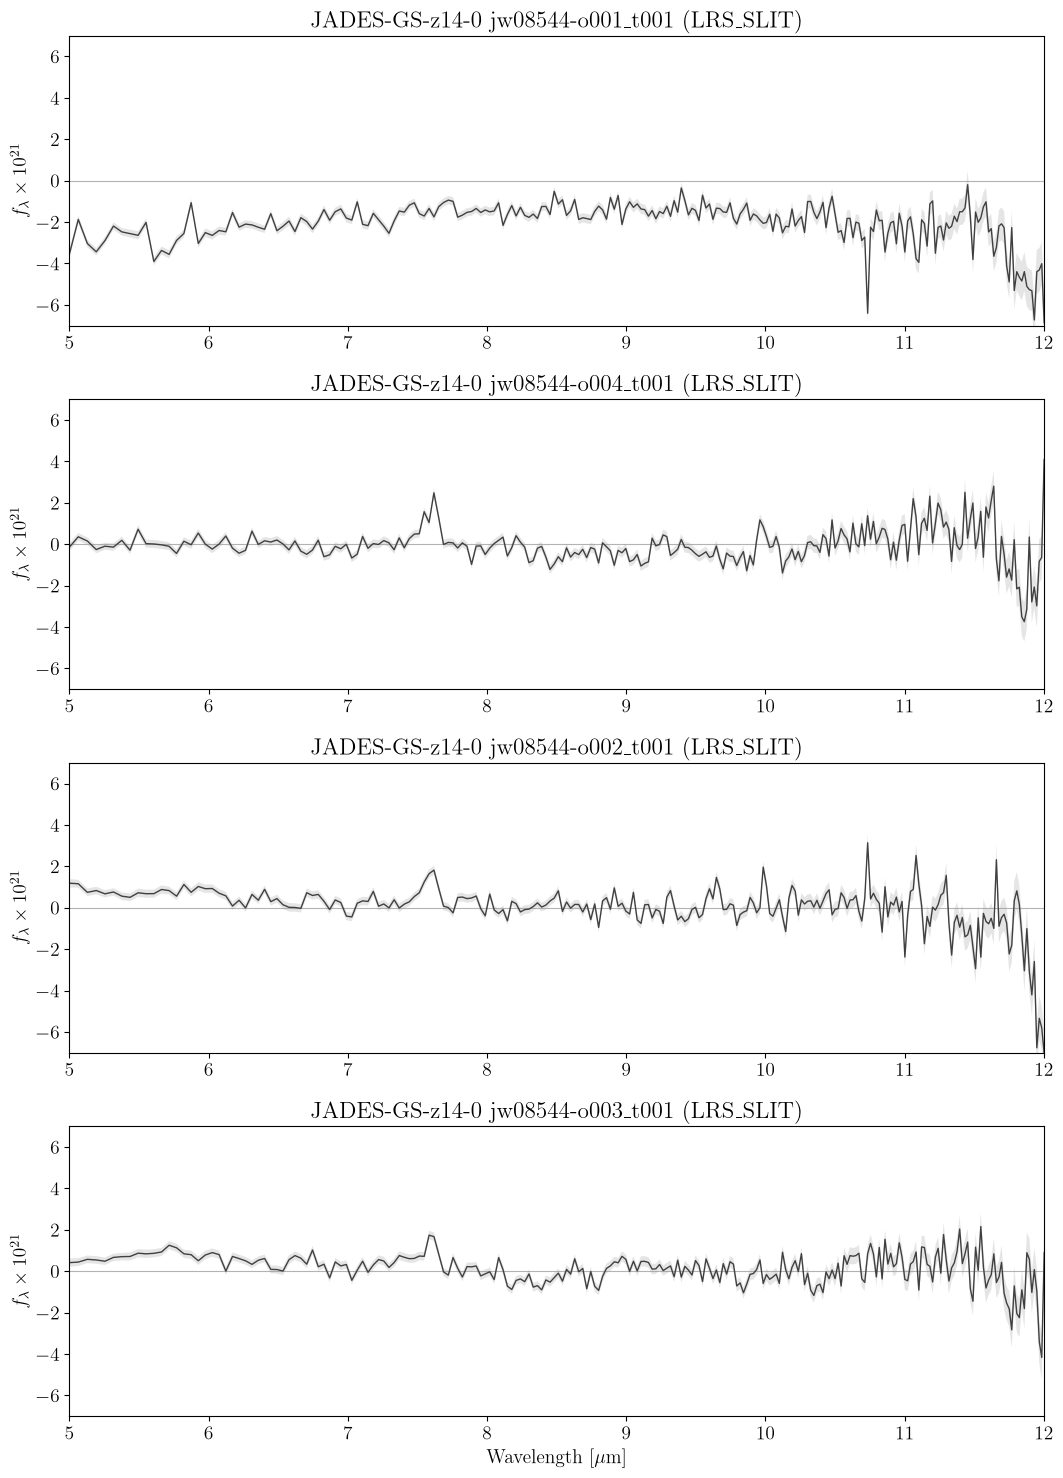

In [18]:
plt.rcParams.update({"font.size": 14})

fig, axes = plt.subplots(len(ok_rows), 1, figsize=(11, 15))

for ax, (_, row) in zip(axes, ok_rows.iterrows()):
    # Read Wavelength [um], Flux / Flux_Error in 1e21 f_lambda units
    spec = pd.read_csv(row["csv_path"])
    wave = spec["Wavelength"].to_numpy(float)
    flux = spec["Flux"].to_numpy(float)
    err = spec["Flux_Error"].to_numpy(float)
    # Sort blue -> red (x1d often stores long to short)
    order = np.argsort(wave)
    wave, flux, err = wave[order], flux[order], err[order]

    ax.fill_between(
        wave, flux - err, flux + err,
        facecolor="0.6", alpha=0.25, edgecolor="none", linewidth=0,
        label=r"$\pm 1\sigma$",
    )
    ax.plot(wave, flux, lw=1.0, color="0.25", label="MIRI LRS")
    ax.axhline(0.0, color="0.7", lw=0.8, zorder=0)
    short_id = str(row["miri_obs_id_download"]).replace("_miri_p750l", "")
    ax.set_title(rf"{row['name']}  {short_id}  ({row['mode']})")
    ax.set_ylabel(r"$f_\lambda \times 10^{21}$")
    ax.set_xlim(5, 12)
    ax.set_ylim(-7, 7)

axes[-1].set_xlabel(r"Wavelength [$\mu$m]")
# axes[0].legend(loc="upper right", fontsize=10)
fig.tight_layout()